In [8]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import json
import subprocess
import scipy.stats as stats
from nilearn import image, masking
import nibabel as nib
Dir_github = '/work/desai-lab/xuanyang/Project/ABC/github'
Dir_dataset = '/work/desai-lab/ABC_dataset'
Dir_preprocess = os.path.join(Dir_dataset,'derivatives','fmriprep')
project = 'ABC_valence'

In [2]:
df_master = pd.read_csv(os.path.join(Dir_github,'derivatives','test_Fam','df_master_Fam120.csv'))
# dfs_eprime = pd.read_csv(os.path.join(Dir_github,'derivatives','test_Fam','dfs_eprime_Fam_by1361.csv'))
df_master

,subid,visit,Fam_fmri,Fam_eprime,age,sex,trans_x,trans_y,trans_z,rot_x,rot_y,rot_z,motion_max
0,1005,1.0,1.0,1.0,65.0,2.0,0.041617,0.267869,0.463099,0.007059,0.003916,0.003123,0.463099
1,1007,1.0,1.0,1.0,69.0,2.0,0.383059,0.671302,0.386057,0.009304,0.001248,0.003724,0.671302
2,1008,1.0,1.0,1.0,77.0,2.0,0.075486,0.203145,0.118612,0.005849,0.000214,0.001656,0.203145
3,1009,1.0,1.0,1.0,75.0,2.0,0.000065,0.349682,0.215196,0.003958,0.000177,0.000196,0.349682
4,1018,1.0,1.0,1.0,60.0,2.0,0.026452,0.412780,0.433625,0.003764,0.005943,0.000393,0.433625
...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,1302,1.0,1.0,1.0,23.0,1.0,0.565818,0.318678,0.295166,0.004322,0.001432,0.012690,0.565818
116,1305,1.0,1.0,1.0,61.0,2.0,0.061026,0.375817,0.324899,0.005508,0.000556,0.000923,0.375817
117,1306,1.0,1.0,1.0,28.0,2.0,0.485715,0.411004,0.707648,0.018751,0.001389,0.016267,0.707648
118,1311,1.0,1.0,1.0,20.0,2.0,0.174499,0.285192,0.111143,0.003649,0.008804,0.005942,0.285192


In [42]:
nWM = 3
nCSF = 3
nPolort = 4
nMotion = 6
censor = 1


contrast = 'BtnPrs'
pipeline_clean = f"test_Fam_mot{nMotion}csf{nCSF}wm{nWM}plt{nPolort}cen{censor}"
pipeline = f"{pipeline_clean}_{contrast}"

Dir_clean = os.path.join(Dir_github,'derivatives',pipeline_clean)
Dir_pipeline = os.path.join(Dir_github,'derivatives',pipeline)
if not os.path.exists(os.path.join(Dir_pipeline,'results','secondlevel')):
#     os.makedirs(Dir_pipeline)
    os.makedirs(os.path.join(Dir_pipeline,'results','secondlevel'))
pipeline

'test_Fam_mot6csf3wm3plt4cen1_BtnPrs'

In [43]:
Dir_firstlevel = os.path.join(Dir_pipeline,'results','firstlevel')
Dir_secondlevel = os.path.join(Dir_pipeline,'results','secondlevel')
df_master['cplt'] = 0
df_master['statImg'] = ''
for i, row in df_master.iterrows():
    subid = int(row['subid'])
    visit = int(row['visit'])
    Dir_subject = os.path.join(Dir_pipeline,'results','firstlevel',f"sub-{subid}",f"sub-{subid}.results")
#     Dir_output = os.path.join(Dir_pipeline,'results','firstlevel',f'sub-{subid}')
    img = os.path.join(Dir_subject,f'stats.sub-{subid}_REML+tlrc.BRIK')
    if os.path.exists(img):
        df_master.loc[i,'cplt'] = 1
        df_master.loc[i,'statImg'] = img
df_master_ana = df_master.loc[df_master['cplt']==1]
df_master_ana

,subid,visit,Fam_fmri,Fam_eprime,age,sex,trans_x,trans_y,trans_z,rot_x,rot_y,rot_z,motion_max,cplt,statImg


In [36]:
import subprocess
import pandas as pd

def get_subbricks_info(dataset):
    # Run 3dinfo command
    result = subprocess.run(['/work/apps/AFNI/linux_openmp_64/3dinfo', '-verb', dataset], capture_output=True, text=True)
    lines = result.stdout.split('\n')
    
    # Extract lines with sub-brick info
    subbrick_lines = [line for line in lines if "sub-brick" in line]
    
    # Extract indices and names from those lines
    subbricks = []
    for line in subbrick_lines:
        idx = int(line.split('#')[1].split()[0])
        name = line.split("'")[1]
        subbricks.append((idx, name))
        
    return subbricks

df_subbricks = pd.DataFrame(get_subbricks_info(df_master_ana.statImg[0]),columns=['imgID', 'regName'])
df_regModel = df_subbricks.loc[df_subbricks['imgID'].isin([8,11])].copy()
# df_regModel['contrast'] = df_regModel['regName'].str.replace('#0_Coef','')
df_regModel['contrast'] = ['btnprs','word_pic']
df_regModel

,imgID,regName,contrast
8,8,btn#0_Tstat,btnprs
11,11,word_pic#0_Tstat,word_pic


In [37]:
threshold = 'p05'
p_cutoff = 0.05 
mask = '/work/desai-lab/xuanyang/Project/ABC/github/ABC_valence/scripts/check_preprocessing/masks/mask_CSFprob99_Fam120.nii.gz'

df_summary = []
for i,row in df_regModel.iterrows():
    contrast = row['contrast']
    imgID = row['imgID']
    Dir_output = os.path.join(Dir_pipeline,'results','firstlevel_CSFact',threshold,contrast)
    if not os.path.exists(Dir_output):
        os.makedirs(Dir_output)
        
    for idx, row_sub in df_master_ana.iterrows():
        subid = int(row_sub['subid'])
        img = os.path.join(Dir_output,f"sub-{subid}_T_{contrast}.nii")
        img_subbrik = f"{row_sub['statImg'].replace('.BRIK','')}'[{str(imgID)}]'"
        
        if not os.path.exists(img): # nilearn only works on nii file
            command = f"/work/apps/AFNI/linux_openmp_64/3dAFNItoNIFTI -prefix {img} {img_subbrik}"
            subprocess.run(command,shell=True)
        
        # get the t-test df and cutoff score
        command = f"/work/apps/AFNI/linux_openmp_64/3dinfo {img_subbrik}"
        result = subprocess.run(command,capture_output=True,text=True,shell=True)
        Df = int(result.stdout.split('statpar = ')[1].split('\n')[0])
        t_cutoff = stats.t.ppf(1 - p_cutoff / 2, Df)  

        # apply the CSF mask
        img_nii = nib.load(img)
        img_mask = nib.load(mask)  # Replace with the path to your mask file
        data_CSF = masking.apply_mask(img_nii, img_mask)
        data_CSF_threshold = data_CSF[data_CSF>t_cutoff]
        
        df_summary.append(pd.DataFrame({'subid':subid,'contrast':contrast,'#voxels_activated':data_CSF_threshold.shape[0],'threshold':p_cutoff,
                      'Df':Df,'T_cutoff':t_cutoff,},index=[0]))
df_summary=pd.concat(df_summary,ignore_index=True)
df_summary.to_csv(os.path.join(Dir_pipeline,'results','firstlevel_CSFact',threshold,f"{pipeline}_CSFact.csv"),index=False)

++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-bit]
++ 3dAFNItoNIFTI: AFNI version=AFNI_21.1.01 (Apr  9 2021) [64-

## Comparison

In [51]:
dfs_comparison = []
for nPC in [5,7]:
    for npol in [2,4,6]:
        nWM = nPC
        nCSF = nPC
        nPolort = npol
        nMotion = 6
        censor = 1
        contrast = 'BtnPrs'
        pipeline_clean = f"test_Fam_mot{nMotion}csf{nCSF}wm{nWM}plt{nPolort}cen{censor}"
        pipeline = f"{pipeline_clean}_{contrast}"
        Dir_pipeline = os.path.join(Dir_github,'derivatives',pipeline)
        df = pd.read_csv(os.path.join(Dir_pipeline,'results','firstlevel_CSFact',threshold,f"{pipeline}_CSFact.csv"))
        df[['nWM','nCSF','nPolort','pipeline']] = [nWM,nCSF,nPolort,pipeline]
        dfs_comparison.append(df)
dfs_comparison = pd.concat(dfs_comparison,ignore_index=True)
dfs_comparison['%voxels_activated'] = dfs_comparison['#voxels_activated']/data_CSF.shape[0]*100
dfs_comparison

,subid,contrast,#voxels_activated,threshold,Df,T_cutoff,nWM,nCSF,nPolort,pipeline,%voxels_activated
0,1005,btnprs,107,0.05,449,1.965261,5,5,2,test_Fam_mot6csf5wm5plt2cen1_BtnPrs,3.290283
1,1007,btnprs,105,0.05,492,1.964797,5,5,2,test_Fam_mot6csf5wm5plt2cen1_BtnPrs,3.228782
2,1008,btnprs,63,0.05,492,1.964797,5,5,2,test_Fam_mot6csf5wm5plt2cen1_BtnPrs,1.937269
3,1009,btnprs,71,0.05,492,1.964797,5,5,2,test_Fam_mot6csf5wm5plt2cen1_BtnPrs,2.183272
4,1018,btnprs,46,0.05,492,1.964797,5,5,2,test_Fam_mot6csf5wm5plt2cen1_BtnPrs,1.414514
...,...,...,...,...,...,...,...,...,...,...,...
1411,1302,word_pic,74,0.05,492,1.964797,7,7,6,test_Fam_mot6csf7wm7plt6cen1_BtnPrs,2.275523
1412,1305,word_pic,91,0.05,492,1.964797,7,7,6,test_Fam_mot6csf7wm7plt6cen1_BtnPrs,2.798278
1413,1306,word_pic,112,0.05,492,1.964797,7,7,6,test_Fam_mot6csf7wm7plt6cen1_BtnPrs,3.444034
1414,1311,word_pic,154,0.05,492,1.964797,7,7,6,test_Fam_mot6csf7wm7plt6cen1_BtnPrs,4.735547


<Axes: xlabel='%voxels_activated', ylabel='Count'>

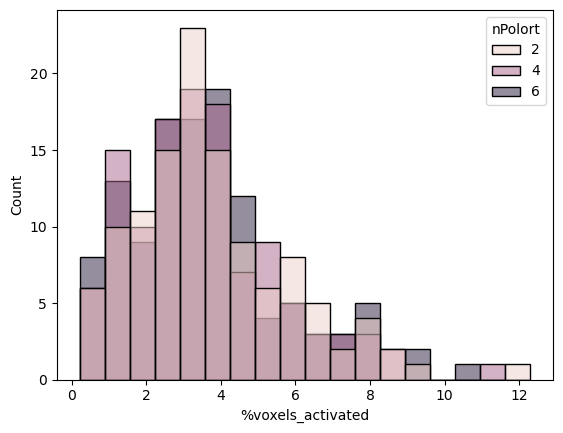

In [55]:
contrast = 'btnprs'
nCSF = 5
df_plot = dfs_comparison.loc[dfs_comparison['contrast']==contrast].loc[dfs_comparison['nCSF']==5]
sns.histplot(df_plot,x='%voxels_activated',hue='nPolort')

<Axes: xlabel='nPolort', ylabel='%voxels_activated'>

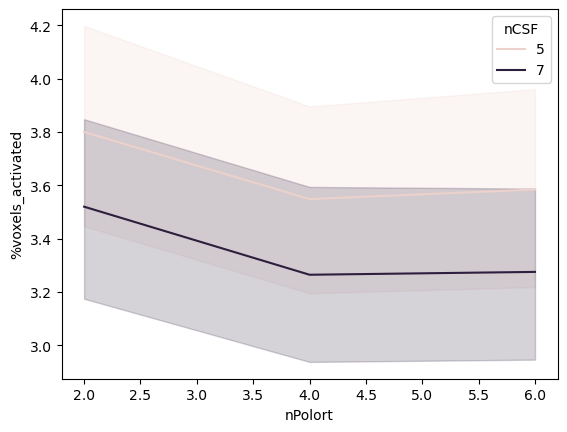

In [57]:
contrast = 'btnprs'
nCSF = 5
df_plot = dfs_comparison.loc[dfs_comparison['contrast']==contrast]
sns.lineplot(df_plot,y='%voxels_activated',x='nPolort',hue='nCSF')

<Axes: xlabel='nPolort', ylabel='%voxels_activated'>

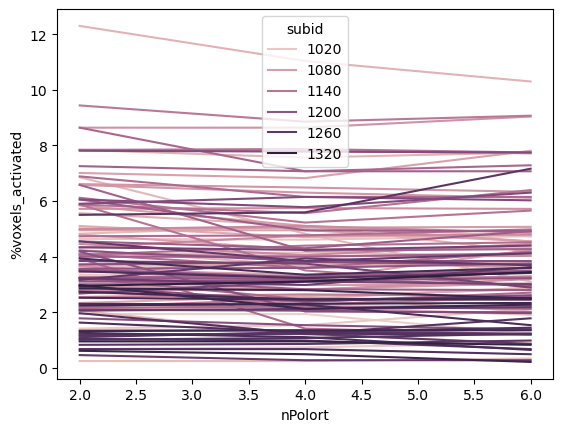

In [59]:
contrast = 'btnprs'
nCSF = 5
df_plot = dfs_comparison.loc[dfs_comparison['contrast']==contrast].loc[dfs_comparison['nCSF']==5]
sns.lineplot(df_plot,y='%voxels_activated',x='nPolort',hue='subid')

,subid,contrast,#voxels_activated,threshold,Df,T_cutoff,%voxels_activated
0,1005,btnprs,103,0.05,449,1.965261,3.167282
1,1007,btnprs,102,0.05,492,1.964797,3.136531
2,1008,btnprs,63,0.05,492,1.964797,1.937269
3,1009,btnprs,72,0.05,492,1.964797,2.214022
4,1018,btnprs,50,0.05,492,1.964797,1.537515
...,...,...,...,...,...,...,...
231,1302,word_pic,176,0.05,492,1.964797,5.412054
232,1305,word_pic,52,0.05,492,1.964797,1.599016
233,1306,word_pic,121,0.05,492,1.964797,3.720787
234,1311,word_pic,99,0.05,492,1.964797,3.044280


In [148]:
df_summary['%voxels_activated'] = df_summary['#voxels_activated']/data_CSF.shape[0]*100
df_summary

,subid,contrast,#voxels_activated,threshold,Df,T_cutoff,%voxels_activated
0,1005,btnprs,107.0,0.05,449,1.965261,3.290283
1,1007,btnprs,105.0,0.05,492,1.964797,3.228782
2,1008,btnprs,63.0,0.05,492,1.964797,1.937269
3,1009,btnprs,71.0,0.05,492,1.964797,2.183272
4,1018,btnprs,46.0,0.05,492,1.964797,1.414514
...,...,...,...,...,...,...,...
231,1302,word_pic,151.0,0.05,492,1.964797,4.643296
232,1305,word_pic,53.0,0.05,492,1.964797,1.629766
233,1306,word_pic,122.0,0.05,492,1.964797,3.751538
234,1311,word_pic,98.0,0.05,492,1.964797,3.013530


<Axes: xlabel='%voxels_activated', ylabel='Count'>

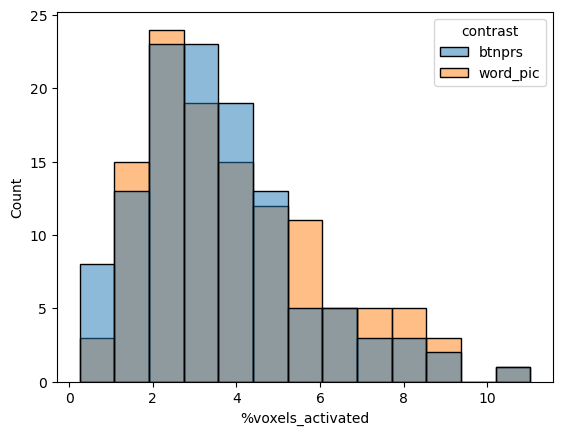

In [11]:
sns.histplot(df_summary,x='%voxels_activated',hue='contrast')

<Axes: xlabel='%voxels_activated', ylabel='Count'>

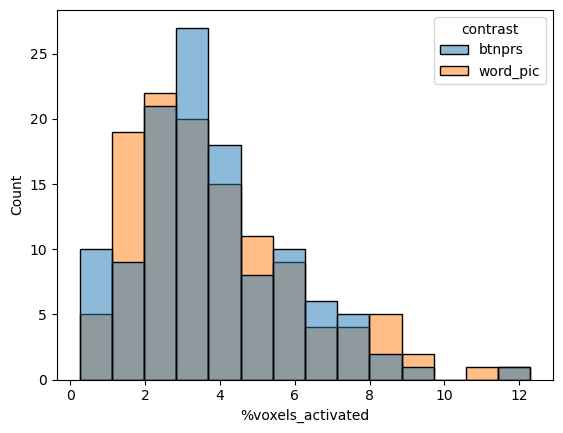

In [149]:
sns.histplot(df_summary,x='%voxels_activated',hue='contrast')

<Axes: xlabel='contrast', ylabel='subid'>

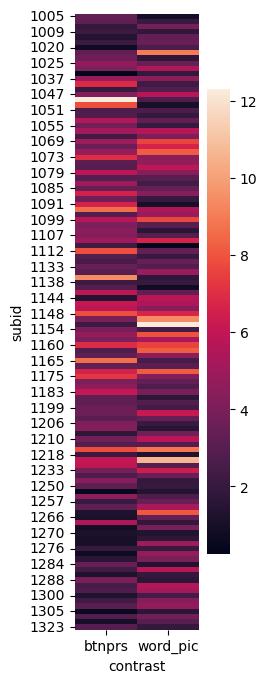

In [150]:
df_plot = df_summary.pivot(index='subid',columns=['contrast'],values='%voxels_activated')
fig,ax = plt.subplots(1,1,figsize=(2,8),dpi=100)
sns.heatmap(df_plot,ax=ax)

In [152]:
df_summary.loc[df_summary['#voxels_activated']==df_summary['#voxels_activated'].max()]

,subid,contrast,#voxels_activated,threshold,Df,T_cutoff,%voxels_activated
16,1048,btnprs,400.0,0.05,492,1.964797,12.300123
